In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

NOTEBOOK 01: RAG FUNDAMENTALS & SEMANTIC SEARCH
===============================================

Workshop: Knowledge Management dengan LLM untuk OMBUDSMAN RI

Durasi: 30 menit (10.00-10.30)

Oleh: Assoc. Prof. Dr. Eng. Farrikh Alzami, M.Kom

Tujuan:
- Memahami konsep embedding dan semantic similarity
- Perbedaan keyword search vs semantic search
- Dasar-dasar bagaimana LLM memahami konteks

Prerequisites:
- Python 3.8+
- Internet connection untuk download models


# SECTION 1: SETUP & INSTALASI

In [2]:
# Install required packages
# Jalankan cell ini sekali saja di awal
import sys
print("Installing required packages...")
print("This may take 2-3 minutes on first run...")

requirements = [
    "sentence-transformers",
    "umap-learn"
]

for package in requirements:
    print(f"Installing {package}...")
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

print("\n Instalasi selesai!")

Installing required packages...
This may take 2-3 minutes on first run...
Installing sentence-transformers...
Installing umap-learn...

 Instalasi selesai!


# SECTION 2: IMPORT LIBRARIES

In [3]:
import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
import torch
import warnings
warnings.filterwarnings('ignore')

# Create output directories
os.makedirs('output_tables', exist_ok=True)
os.makedirs('output_figures', exist_ok=True)

# Set random seed untuk reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Konfigurasi plotting
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print(" Libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")


2026-02-07 15:00:45.553338: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1770476445.812505      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1770476445.905801      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1770476446.524678      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1770476446.524766      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1770476446.524770      55 computation_placer.cc:177] computation placer alr

 Libraries imported successfully!
PyTorch version: 2.8.0+cu126
CUDA available: False


# SECTION 3: LOAD MODEL EMBEDDING

Kita akan menggunakan XLM-RoBERTa yang support Bahasa Indonesia.

Model ini:
- Trained pada 100+ bahasa termasuk Indonesia
- Menghasilkan embedding 768-dimensional
- Cocok untuk semantic search pada dokumen bahasa Indonesia

In [4]:
print("Loading XLM-RoBERTa model...")
print("First run akan download ~1GB model - sekitar 2-3 menit")
print("Subsequent runs akan instant karena cached\n")

# Load model
model_name = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
model = SentenceTransformer(model_name)

print(f" Model loaded: {model_name}")
print(f"   Embedding dimension: {model.get_sentence_embedding_dimension()}")
print(f"   Max sequence length: {model.max_seq_length} tokens")


Loading XLM-RoBERTa model...
First run akan download ~1GB model - sekitar 2-3 menit
Subsequent runs akan instant karena cached



modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

 Model loaded: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
   Embedding dimension: 384
   Max sequence length: 128 tokens


# SECTION 4: DEMO DASAR - SEMANTIC SIMILARITY

Demo 1: Memahami Semantic Similarity
-------------------------------------
Kita akan compare 3 kalimat dan lihat similarity scores

In [5]:
print("\n" + "="*80)
print("DEMO 1: SEMANTIC SIMILARITY - MEMAHAMI DASAR")
print("="*80 + "\n")

# Contoh kalimat dalam konteks OMBUDSMAN
kalimat_1 = "Saya ingin mengajukan pengaduan terhadap pelayanan publik yang buruk"
kalimat_2 = "Bagaimana cara melaporkan keluhan tentang layanan pemerintah yang tidak memuaskan"
kalimat_3 = "Cuaca hari ini sangat cerah dan menyenangkan"

kalimat_list = [kalimat_1, kalimat_2, kalimat_3]

# Generate embeddings
print("Generating embeddings...")
embeddings = model.encode(kalimat_list, convert_to_tensor=False)

print(f"Embedding shape: {embeddings.shape}")
print(f"Setiap kalimat direpresentasikan sebagai vector {embeddings.shape[1]}-dimensional\n")

# Hitung cosine similarity
similarity_matrix = cosine_similarity(embeddings)

# Tampilkan hasil
print("KALIMAT:")
for i, kalimat in enumerate(kalimat_list):
    print(f"{i+1}. {kalimat}")

print("\n" + "-"*80)
print("SIMILARITY SCORES (0.0 = tidak mirip, 1.0 = identik):")
print("-"*80)

for i in range(len(kalimat_list)):
    for j in range(i+1, len(kalimat_list)):
        score = similarity_matrix[i][j]
        print(f"Kalimat {i+1} vs Kalimat {j+1}: {score:.4f}")
        
print("\n INSIGHT:")
print("   - Kalimat 1 & 2 memiliki similarity TINGGI (semantic mirip)")
print("   - Kalimat 1 & 3 memiliki similarity RENDAH (semantic berbeda)")
print("   - Meskipun kata-katanya berbeda, model memahami MAKNA yang sama!\n")



DEMO 1: SEMANTIC SIMILARITY - MEMAHAMI DASAR

Generating embeddings...
Embedding shape: (3, 384)
Setiap kalimat direpresentasikan sebagai vector 384-dimensional

KALIMAT:
1. Saya ingin mengajukan pengaduan terhadap pelayanan publik yang buruk
2. Bagaimana cara melaporkan keluhan tentang layanan pemerintah yang tidak memuaskan
3. Cuaca hari ini sangat cerah dan menyenangkan

--------------------------------------------------------------------------------
SIMILARITY SCORES (0.0 = tidak mirip, 1.0 = identik):
--------------------------------------------------------------------------------
Kalimat 1 vs Kalimat 2: 0.6077
Kalimat 1 vs Kalimat 3: -0.1406
Kalimat 2 vs Kalimat 3: -0.0736

 INSIGHT:
   - Kalimat 1 & 2 memiliki similarity TINGGI (semantic mirip)
   - Kalimat 1 & 3 memiliki similarity RENDAH (semantic berbeda)
   - Meskipun kata-katanya berbeda, model memahami MAKNA yang sama!



# SECTION 5: VISUALISASI EMBEDDING SPACE

Demo 2: Visualisasi Embedding Space dengan UMAP
------------------------------------------------
Kita akan project 768-dim embeddings ke 2D untuk visualisasi


DEMO 2: VISUALISASI EMBEDDING SPACE

Encoding 20 dokumen samples...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]


Reducing dimensionality dengan UMAP...


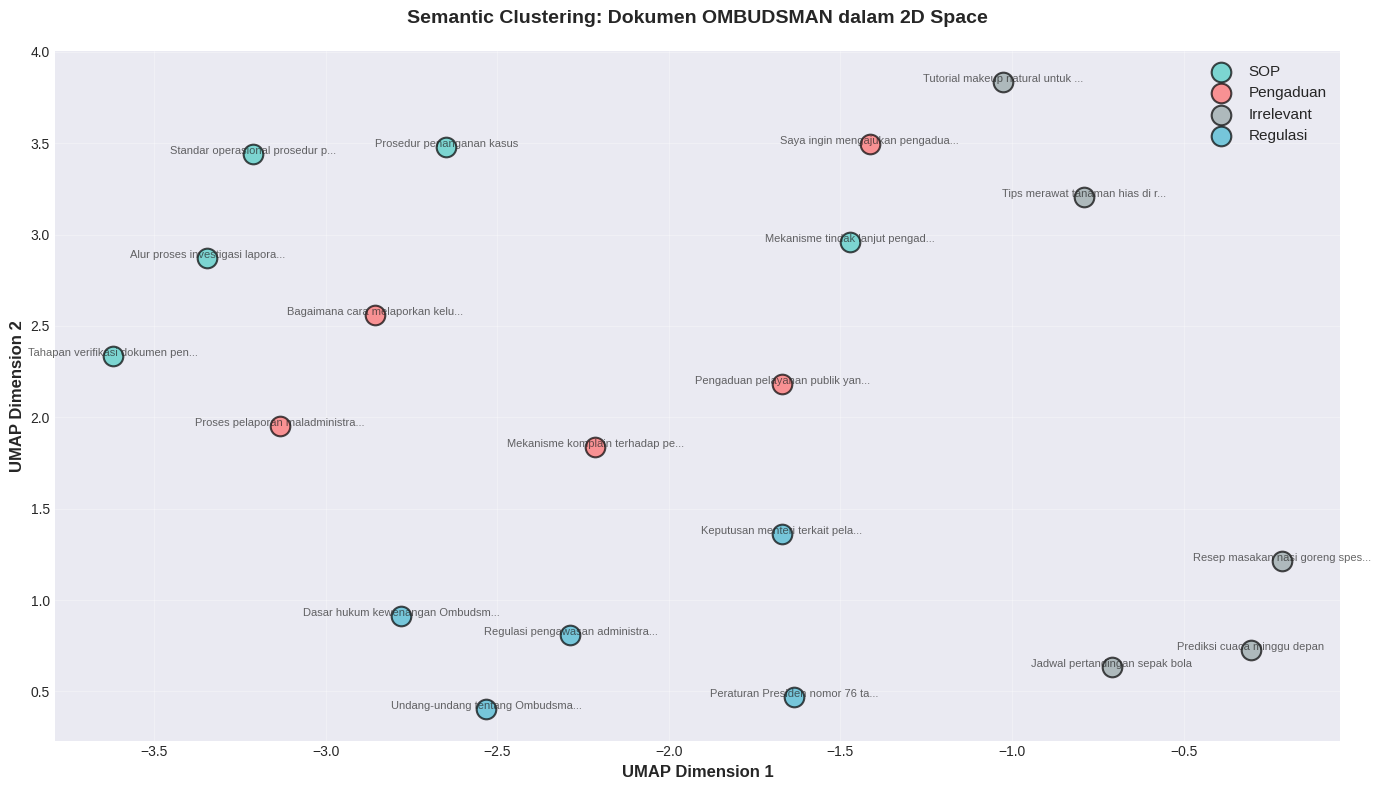

Figure saved to: output_figures/semantic_clustering.png


<Figure size 1200x600 with 0 Axes>


 INSIGHT dari visualisasi:
   - Dokumen dengan semantic MIRIP clustering berdekatan
   - Dokumen irrelevant terpisah jauh dari clusters utama
   - Model memahami KONTEKS, bukan hanya keyword matching!
   - Ini dasar dari SEMANTIC SEARCH dalam RAG system



In [6]:
from umap import UMAP

print("\n" + "="*80)
print("DEMO 2: VISUALISASI EMBEDDING SPACE")
print("="*80 + "\n")

# Buat dataset lebih besar untuk visualisasi yang lebih jelas
dokumen_samples = [
    # Cluster 1: Pengaduan/Complaint
    "Saya ingin mengajukan pengaduan",
    "Bagaimana cara melaporkan keluhan",
    "Proses pelaporan maladministrasi",
    "Pengaduan pelayanan publik yang buruk",
    "Mekanisme komplain terhadap pejabat",
    
    # Cluster 2: SOP/Prosedur
    "Standar operasional prosedur pemeriksaan",
    "Tahapan verifikasi dokumen pengaduan",
    "Alur proses investigasi laporan",
    "Prosedur penanganan kasus",
    "Mekanisme tindak lanjut pengaduan",
    
    # Cluster 3: Peraturan/Regulasi
    "Undang-undang tentang Ombudsman",
    "Peraturan Presiden nomor 76 tahun 2013",
    "Keputusan menteri terkait pelayanan publik",
    "Regulasi pengawasan administrasi negara",
    "Dasar hukum kewenangan Ombudsman",
    
    # Cluster 4: Irrelevant (untuk kontras)
    "Resep masakan nasi goreng spesial",
    "Tips merawat tanaman hias di rumah",
    "Prediksi cuaca minggu depan",
    "Jadwal pertandingan sepak bola",
    "Tutorial makeup natural untuk pemula"
]

labels = (
    ["Pengaduan"]*5 + 
    ["SOP"]*5 + 
    ["Regulasi"]*5 + 
    ["Irrelevant"]*5
)

print(f"Encoding {len(dokumen_samples)} dokumen samples...")
doc_embeddings = model.encode(dokumen_samples, show_progress_bar=True)

print("\nReducing dimensionality dengan UMAP...")
# UMAP: Dimensionality reduction untuk visualisasi
umap_model = UMAP(
    n_components=2,
    n_neighbors=5,
    min_dist=0.1,
    metric='cosine',
    random_state=42
)

embeddings_2d = umap_model.fit_transform(doc_embeddings)

# Plot
fig, ax = plt.subplots(figsize=(14, 8))

colors = {'Pengaduan': '#FF6B6B', 'SOP': '#4ECDC4', 
          'Regulasi': '#45B7D1', 'Irrelevant': '#95A5A6'}

for label in set(labels):
    mask = np.array(labels) == label
    ax.scatter(
        embeddings_2d[mask, 0], 
        embeddings_2d[mask, 1],
        c=colors[label],
        label=label,
        s=200,
        alpha=0.7,
        edgecolors='black',
        linewidth=1.5
    )

# Annotate points
for i, txt in enumerate(dokumen_samples):
    # Truncate text untuk readability
    short_txt = txt[:30] + "..." if len(txt) > 30 else txt
    ax.annotate(
        short_txt, 
        (embeddings_2d[i, 0], embeddings_2d[i, 1]),
        fontsize=8,
        alpha=0.7,
        ha='center'
    )

ax.set_xlabel('UMAP Dimension 1', fontsize=12, fontweight='bold')
ax.set_ylabel('UMAP Dimension 2', fontsize=12, fontweight='bold')
ax.set_title('Semantic Clustering: Dokumen OMBUDSMAN dalam 2D Space', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(fontsize=11, loc='best')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

fig_path = 'output_figures/semantic_clustering.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Figure saved to: {fig_path}")

plt.show()

print("\n INSIGHT dari visualisasi:")
print("   - Dokumen dengan semantic MIRIP clustering berdekatan")
print("   - Dokumen irrelevant terpisah jauh dari clusters utama")
print("   - Model memahami KONTEKS, bukan hanya keyword matching!")
print("   - Ini dasar dari SEMANTIC SEARCH dalam RAG system\n")


# SECTION 6: KEYWORD SEARCH VS SEMANTIC SEARCH

Demo 3: Head-to-Head Comparison
--------------------------------
Bandingkan keyword search (naive) vs semantic search (LLM-based)

In [7]:
print("\n" + "="*80)
print("DEMO 3: KEYWORD SEARCH VS SEMANTIC SEARCH")
print("="*80 + "\n")

# Knowledge base simulasi: dokumen SOP Ombudsman
knowledge_base = [
    {
        "id": "DOC001",
        "title": "SOP Penerimaan Pengaduan Masyarakat",
        "content": "Prosedur standar untuk menerima dan mendokumentasikan keluhan dari masyarakat terkait maladministrasi pelayanan publik. Termasuk verifikasi identitas pelapor dan klasifikasi jenis pengaduan."
    },
    {
        "id": "DOC002",
        "title": "Tata Cara Investigasi Laporan",
        "content": "Tahapan investigasi dimulai dari penelaahan awal, pengumpulan bukti, wawancara saksi, hingga penyusunan rekomendasi. Setiap tahap harus terdokumentasi dengan baik."
    },
    {
        "id": "DOC003",
        "title": "Kewenangan Ombudsman RI",
        "content": "Ombudsman memiliki kewenangan mengawasi penyelenggaraan pelayanan publik, melakukan investigasi atas laporan masyarakat, dan memberikan rekomendasi perbaikan kepada instansi terkait."
    },
    {
        "id": "DOC004",
        "title": "Mekanisme Tindak Lanjut Rekomendasi",
        "content": "Rekomendasi Ombudsman wajib ditindaklanjuti oleh instansi terlapor dalam waktu 60 hari. Monitoring dilakukan secara berkala untuk memastikan implementasi."
    },
    {
        "id": "DOC005",
        "title": "Persyaratan Pengaduan yang Dapat Diterima",
        "content": "Pengaduan harus memenuhi syarat administratif: identitas jelas, uraian kronologi, dan bukti pendukung. Pengaduan anonim tidak dapat diproses sesuai regulasi."
    }
]

# Encode semua dokumen dalam knowledge base
print("Encoding knowledge base...")
kb_texts = [doc["content"] for doc in knowledge_base]
kb_embeddings = model.encode(kb_texts, show_progress_bar=False)

print(f" Knowledge base ready: {len(knowledge_base)} dokumen\n")



DEMO 3: KEYWORD SEARCH VS SEMANTIC SEARCH

Encoding knowledge base...
 Knowledge base ready: 5 dokumen



# Query Test

In [8]:
query = "Bagaimana syarat untuk mengajukan komplain?"

print(f"QUERY: \"{query}\"\n")
print("-"*80)

# METHOD 1: Keyword Search (Naive)
print("\n METHOD 1: KEYWORD SEARCH (NAIVE)")
print("-"*80)

# Simple keyword matching
query_keywords = set(query.lower().split())
keyword_scores = []

for doc in knowledge_base:
    doc_words = set(doc["content"].lower().split())
    # Hitung berapa keyword yang match
    matches = len(query_keywords.intersection(doc_words))
    keyword_scores.append(matches)

# Ranking berdasarkan keyword match
keyword_ranking = sorted(
    zip(knowledge_base, keyword_scores),
    key=lambda x: x[1],
    reverse=True
)

print("\nTop 3 Results (Keyword Search):")
for i, (doc, score) in enumerate(keyword_ranking[:3], 1):
    print(f"\n{i}. {doc['title']} (Score: {score} keyword matches)")
    print(f"   ID: {doc['id']}")
    print(f"   Content preview: {doc['content'][:100]}...")

# METHOD 2: Semantic Search
print("\n\n METHOD 2: SEMANTIC SEARCH (LLM-BASED)")
print("-"*80)

# Encode query
query_embedding = model.encode([query], show_progress_bar=False)

# Hitung similarity dengan semua docs
semantic_scores = cosine_similarity(query_embedding, kb_embeddings)[0]

# Ranking berdasarkan semantic similarity
semantic_ranking = sorted(
    zip(knowledge_base, semantic_scores),
    key=lambda x: x[1],
    reverse=True
)

print("\nTop 3 Results (Semantic Search):")
for i, (doc, score) in enumerate(semantic_ranking[:3], 1):
    print(f"\n{i}. {doc['title']} (Similarity: {score:.4f})")
    print(f"   ID: {doc['id']}")
    print(f"   Content preview: {doc['content'][:100]}...")


QUERY: "Bagaimana syarat untuk mengajukan komplain?"

--------------------------------------------------------------------------------

 METHOD 1: KEYWORD SEARCH (NAIVE)
--------------------------------------------------------------------------------

Top 3 Results (Keyword Search):

1. SOP Penerimaan Pengaduan Masyarakat (Score: 1 keyword matches)
   ID: DOC001
   Content preview: Prosedur standar untuk menerima dan mendokumentasikan keluhan dari masyarakat terkait maladministras...

2. Mekanisme Tindak Lanjut Rekomendasi (Score: 1 keyword matches)
   ID: DOC004
   Content preview: Rekomendasi Ombudsman wajib ditindaklanjuti oleh instansi terlapor dalam waktu 60 hari. Monitoring d...

3. Persyaratan Pengaduan yang Dapat Diterima (Score: 1 keyword matches)
   ID: DOC005
   Content preview: Pengaduan harus memenuhi syarat administratif: identitas jelas, uraian kronologi, dan bukti pendukun...


 METHOD 2: SEMANTIC SEARCH (LLM-BASED)
------------------------------------------------------

# Comparison Analysis

In [9]:
print("\n\n" + "="*80)
print(" COMPARISON ANALYSIS")
print("="*80 + "\n")

# Create comparison dataframe
comparison_df = pd.DataFrame({
    'Document ID': [doc['id'] for doc in knowledge_base],
    'Title': [doc['title'] for doc in knowledge_base],
    'Keyword Score': keyword_scores,
    'Semantic Score': [f"{score:.4f}" for score in semantic_scores]
})

print(comparison_df.to_string(index=False))

print("\n\n KEY INSIGHTS:")
print("-"*80)
print(" Keyword Search:")
print("  - Hanya match kata-kata eksak (syarat, pengaduan, dll)")
print("  - Gagal memahami MAKNA dari 'komplain' = 'pengaduan'")
print("  - Tidak memahami konteks 'syarat untuk mengajukan'")
print()
print(" Semantic Search:")
print("  - Memahami 'komplain' semantically sama dengan 'pengaduan'")
print("  - Memahami konteks 'syarat' terkait dengan 'persyaratan'")
print("  - Dokumen paling relevan mendapat score tertinggi")
print()
print(" KESIMPULAN:")
print("   Semantic Search jauh lebih POWERFUL untuk:")
print("   - Pencarian dalam bahasa natural")
print("   - Handling sinonim dan variasi bahasa")
print("   - Memahami intent user\n")



 COMPARISON ANALYSIS

Document ID                                     Title  Keyword Score Semantic Score
     DOC001       SOP Penerimaan Pengaduan Masyarakat              1         0.4682
     DOC002             Tata Cara Investigasi Laporan              0         0.3256
     DOC003                   Kewenangan Ombudsman RI              0         0.2323
     DOC004       Mekanisme Tindak Lanjut Rekomendasi              1         0.2628
     DOC005 Persyaratan Pengaduan yang Dapat Diterima              1         0.3264


 KEY INSIGHTS:
--------------------------------------------------------------------------------
 Keyword Search:
  - Hanya match kata-kata eksak (syarat, pengaduan, dll)
  - Gagal memahami MAKNA dari 'komplain' = 'pengaduan'
  - Tidak memahami konteks 'syarat untuk mengajukan'

 Semantic Search:
  - Memahami 'komplain' semantically sama dengan 'pengaduan'
  - Memahami konteks 'syarat' terkait dengan 'persyaratan'
  - Dokumen paling relevan mendapat score tertinggi

